# 01 · Exploración de dunnhumby *The Complete Journey*

**Objetivo del proyecto.** Brújula es un SaaS para PYMEs que responde dos preguntas:

1. **¿Qué tipos de clientes tengo?** → segmentación (notebook 02: K-Means + SVM).
2. **¿Quién va a volver a comprar pronto?** → propensión de compra (notebook 03: LightGBM).

Este notebook entiende los datos y toma las decisiones de diseño que condicionan a los otros dos.

**Datos.** *The Complete Journey* de dunnhumby: un año (2017) de compras de 2.469 hogares en
una cadena de supermercados, con productos, campañas de marketing, cupones y demografía.
Se usa la versión del paquete R [`completejourney`](https://github.com/bradleyboehmke/completejourney)
(licencia CC0), que se descarga sin credenciales.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from brujula_ml import datos
from brujula_ml import features as F
from brujula_ml import graficos as G

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", "{:,.2f}".format)
G.estilo()

datos.preparar()  # descarga (si falta), verifica SHA-256 y convierte a parquet

## 1. ¿Qué hay en los datos?

In [2]:
tablas = {n: datos.cargar(n) for n in datos.ARCHIVOS}
pd.DataFrame(
    {
        "filas": {n: len(t) for n, t in tablas.items()},
        "columnas": {n: t.shape[1] for n, t in tablas.items()},
    }
)

,filas,columnas
transactions,1469307,11
promotions,20940529,5
demographics,801,8
products,92331,7
campaigns,6589,2
campaign_descriptions,27,4
coupons,116204,3
coupon_redemptions,2102,4


In [3]:
tx = F.transacciones()
c = F.cestas(tx)
resumen = pd.Series(
    {
        "Desde": tx["fecha"].min().date(),
        "Hasta": tx["fecha"].max().date(),
        "Hogares": tx["household_id"].nunique(),
        "Cestas (compras)": len(c),
        "Líneas de compra": len(tx),
        "Tiendas": tx["store_id"].nunique(),
        "Productos distintos": tx["product_id"].nunique(),
        "Venta total (USD)": f"{c['total'].sum():,.0f}",
        "Hogares con demografía": len(tablas["demographics"]),
    }
)
resumen.to_frame("valor")

,valor
Desde,2017-01-01
Hasta,2017-12-31
Hogares,2469
Cestas (compras),155762
Líneas de compra,1468773
Tiendas,457
Productos distintos,68500
Venta total (USD),"4,594,146"
Hogares con demografía,801


Dos limpiezas, ya incorporadas en `features.transacciones()`:

- **534 líneas del 1-ene-2018** (madrugada): se descartan; el año analizado es 2017.
- **Combustible**: `FUEL` y parte de `MISCELLANEOUS` registran la lectura del surtidor como
  cantidad (miles por línea). Esas líneas cuentan como 1 unidad.

## 2. Ritmo del negocio

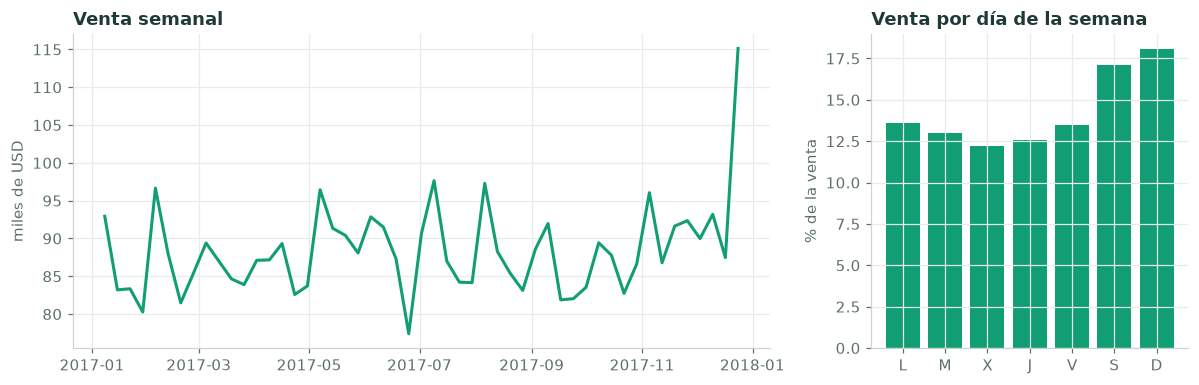

In [4]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [2.2, 1]})
semanal = c.set_index("fecha")["total"].resample("W-SUN").sum().iloc[1:-1]
a1.plot(semanal.index, semanal / 1000, color=G.MARCA, lw=2)
a1.set(title="Venta semanal", ylabel="miles de USD")
dow = c.groupby(c["fecha"].dt.day_of_week)["total"].sum() / c["total"].sum()
a2.bar(["L", "M", "X", "J", "V", "S", "D"], dow * 100, color=G.MARCA)
a2.set(title="Venta por día de la semana", ylabel="% de la venta")
fig.tight_layout()

La venta es estable en el año (sin una estacionalidad fuerte salvo diciembre) y se concentra
en el fin de semana. Que no haya grandes picos simplifica la validación temporal: los cortes
de entrenamiento y de test se parecen.

## 3. ¿Cómo compran los hogares?

,count,mean,std,min,10%,50%,90%,max
cestas,"2,469.00",63.09,69.82,1.00,9.00,43.00,137.00,780.00
gasto,"2,469.00","1,860.73","2,022.24",2.00,175.24,"1,210.02","4,341.97","24,879.75"
ticket,"2,469.00",31.85,20.72,2.00,11.79,27.29,56.42,188.34


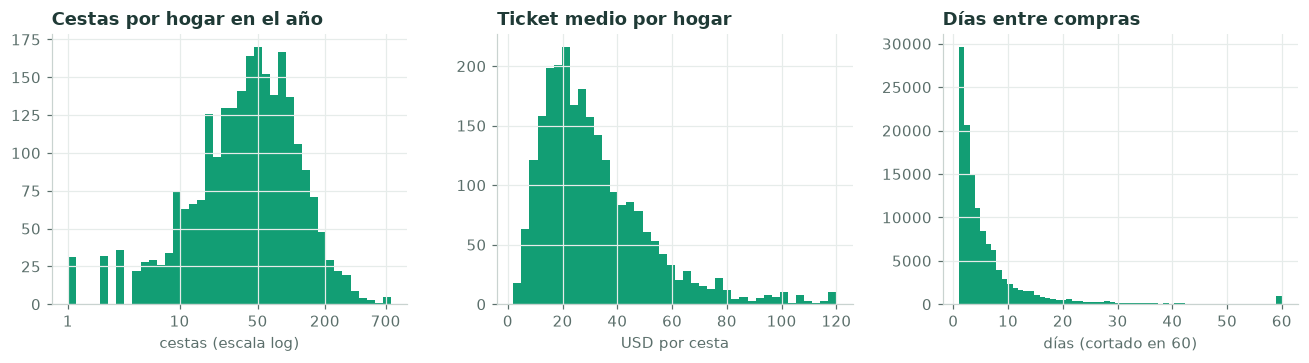

In [5]:
por_hogar = c.groupby("household_id").agg(
    cestas=("basket_id", "size"), gasto=("total", "sum"), ultima=("fecha", "max")
)
por_hogar["ticket"] = por_hogar["gasto"] / por_hogar["cestas"]
dias = c[["household_id", "fecha"]].drop_duplicates().sort_values(["household_id", "fecha"])
intervalo = dias.groupby("household_id")["fecha"].diff().dt.days.dropna()

fig, ejes = plt.subplots(1, 3, figsize=(12, 3.4))
ejes[0].hist(np.log10(por_hogar["cestas"]), bins=40, color=G.MARCA)
ejes[0].set(title="Cestas por hogar en el año", xlabel="cestas (escala log)")
ejes[0].set_xticks(np.log10([1, 10, 50, 200, 700]), ["1", "10", "50", "200", "700"])
ejes[1].hist(por_hogar["ticket"].clip(upper=120), bins=40, color=G.MARCA)
ejes[1].set(title="Ticket medio por hogar", xlabel="USD por cesta")
ejes[2].hist(intervalo.clip(upper=60), bins=60, color=G.MARCA)
ejes[2].set(title="Días entre compras", xlabel="días (cortado en 60)")
fig.tight_layout()
G.guardar(fig, "01_comportamiento")

por_hogar[["cestas", "gasto", "ticket"]].describe(percentiles=[0.1, 0.5, 0.9]).T

Hay una cola larga muy marcada: la mediana es de 43 cestas al año (casi una por semana),
pero el 10 % de los hogares supera las 137. Todas las variables de volumen se transforman
con `log1p` antes de entrar a modelos basados en distancias (K-Means, SVM).

El hogar mediano vuelve **cada 6 días** (la mitad central de los hogares, entre 4 y 11), una
pista clave para la propensión (sección 6).

## 4. ¿Qué compran?

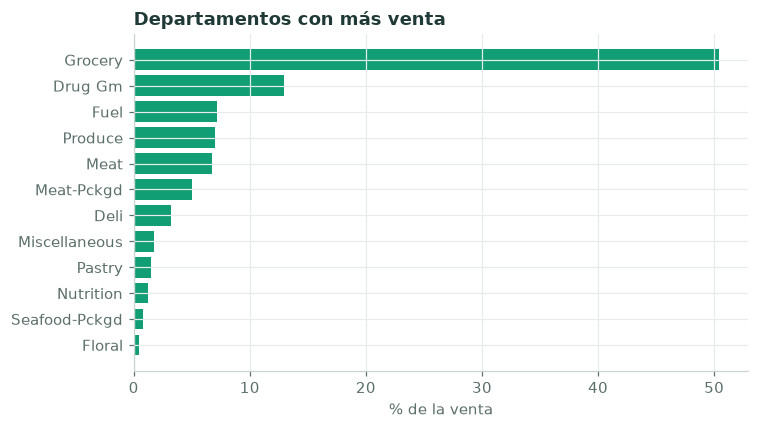

In [6]:
dep = tx.groupby("department")["sales_value"].sum().sort_values().tail(12) / tx["sales_value"].sum()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(dep.index.str.title(), dep * 100, color=G.MARCA)
ax.set(title="Departamentos con más venta", xlabel="% de la venta")
fig.tight_layout()

## 5. Promociones y campañas

In [7]:
recibidas, canjes = F.campanas()
promos = pd.Series(
    {
        "% de cestas con algún descuento": c["con_descuento"].mean() * 100,
        "% de la venta bruta descontada": c["descuento"].sum()
        / (c["total"].sum() + c["descuento"].sum())
        * 100,
        "Hogares que recibieron alguna campaña": recibidas["household_id"].nunique(),
        "Campañas por hogar (mediana, entre quienes recibieron)": recibidas.groupby("household_id")
        .size()
        .median(),
        "Hogares que canjearon algún cupón": canjes["household_id"].nunique(),
    }
)
promos.to_frame("valor")

,valor
% de cestas con algún descuento,83.88
% de la venta bruta descontada,15.18
Hogares que recibieron alguna campaña,"1,559.00"
"Campañas por hogar (mediana, entre quienes recibieron)",4.00
Hogares que canjearon algún cupón,410.00


El descuento es parte de casi todas las cestas, así que "usa promociones" por sí solo
distingue poco. Canjear cupones de campaña es mucho más raro y sí dice algo del cliente.

## 6. Decisión de diseño: ¿qué ventana usar para la propensión?

La app pregunta "¿comprará este cliente en los próximos *N* días?". Para que esa pregunta
sirva, la respuesta no puede ser "sí" para casi todos. Se mide la **tasa base** (qué
proporción de los hogares activos vuelve a comprar) en distintos cortes y ventanas.

,7 días,14 días,30 días
2017-03-31,57.70,74.00,86.00
2017-04-30,59.00,74.70,86.80
2017-05-31,55.90,71.30,84.60
2017-06-30,59.50,73.60,85.60
2017-07-31,58.90,72.80,82.90
2017-08-31,55.90,70.40,82.80
2017-09-30,55.10,70.80,83.20
2017-10-31,55.90,70.70,83.60
2017-11-30,54.50,70.60,82.60


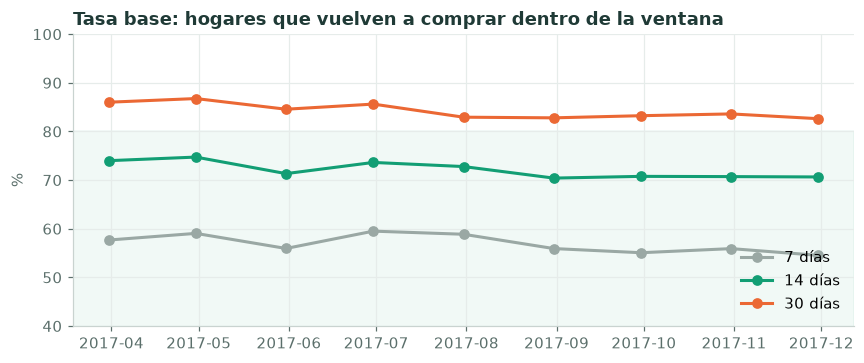

In [8]:
cortes = pd.date_range("2017-03-31", "2017-11-30", freq="ME")
tasa = pd.DataFrame(
    {
        f"{v} días": [
            F.etiqueta_compra(
                c, t, v, pd.Index(c.loc[c["fecha"] <= t, "household_id"].unique())
            ).mean()
            for t in cortes
        ]
        for v in (7, 14, 30)
    },
    index=cortes.date,
)
fig, ax = plt.subplots(figsize=(8, 3.4))
for col, color in zip(tasa.columns, ["#9aa8a4", G.MARCA, "#eb6834"], strict=True):
    ax.plot(tasa.index, tasa[col] * 100, marker="o", color=color, label=col, lw=2)
ax.axhspan(20, 80, color=G.MARCA, alpha=0.06)
ax.set(
    title="Tasa base: hogares que vuelven a comprar dentro de la ventana",
    ylabel="%",
    ylim=(40, 100),
)
ax.legend(loc="lower right")
fig.tight_layout()
G.guardar(fig, "01_tasa_base")
(tasa * 100).round(1)

A 30 días vuelve el **83–86 %** de los hogares: con una tasa base tan alta casi todo el mundo
es "alta propensión" y el modelo tiene poco que ordenar. A **14 días** la tasa baja a ~71 %,
dentro de la franja útil (sombreada), y sigue siendo un horizonte accionable para una campaña.

**Decisión:** la propensión se define como *probabilidad de comprar en los próximos 14 días*.
El dashboard muestra esa ventana para este conjunto de datos.

## 7. Demografía (solo para describir)

Solo 801 de los 2.469 hogares (32 %) tienen datos demográficos. No entran en los modelos
(dejarían fuera a dos tercios de los clientes, y una PYME rara vez tiene esos datos); se usan
en el notebook 02 para describir cada segmento.

In [9]:
demo = tablas["demographics"].merge(por_hogar, left_on="household_id", right_index=True)
orden = [
    "Under 15K",
    "15-24K",
    "25-34K",
    "35-49K",
    "50-74K",
    "75-99K",
    "100-124K",
    "125-149K",
    "150-174K",
    "175-199K",
    "200-249K",
    "250K+",
]
demo.groupby("income", observed=True)["gasto"].median().reindex(orden).to_frame(
    "gasto anual mediano"
)

,gasto anual mediano
income,
Under 15K,"2,462.25"
15-24K,"2,113.83"
25-34K,"2,409.06"
35-49K,"2,377.45"
50-74K,"2,822.66"
75-99K,"2,915.18"
100-124K,"3,217.53"
125-149K,"3,114.57"
150-174K,"4,981.07"


## Conclusiones

- Datos limpios y estables en el año; dos correcciones menores (líneas de 2018, combustible).
- Comportamiento con cola larga → transformación logarítmica para los modelos de distancia.
- El hogar típico compra cada ~6 días → la propensión usa una ventana de **14 días**, no de 30.
- Demografía parcial → solo descriptiva.